# Noisy-oracle FTCI — shot-noise robustness (referee item P0.1)

Repeats the Heisenberg-chain experiment (Sec. VII.D) with a **noisy oracle**:
each unique grid query returns `fq(J) + ε`, with `ε ~ N(0, 1/S)` emulating an
expectation value estimated from `S` shots. Because queries are cached, each grid
point is "measured" exactly once — consistent with a single measurement campaign.

Outputs:
- relative error vs. shots-per-query `S` (with a `1/√S` guide line),
- relative error vs. **total shot budget** `ctr.n × S`,
- oracle-call counts vs. `S`.

Reuses `HeisenbergHybrid.jl` + `FunctionTCI.jl` unchanged.


In [10]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  CONFIGURATION                                                            ║
# ╚══════════════════════════════════════════════════════════════════════════╝

QUICK_MODE = false     # true → N=4, K=2 sanity run (~minutes); false → manuscript run

# ── Physics (matches Sec. VII.D) ─────────────────────────────────────────────
N_SINGLE  = QUICK_MODE ? 4 : 9
N_STEPS   = QUICK_MODE ? 2 : 3       # Trotter steps K
T_EVOLVE  = 1.0

# ── Noise sweep ──────────────────────────────────────────────────────────────
# S = shots per oracle query; Inf = noiseless reference
S_LIST   = QUICK_MODE ? [1e2, 1e4, Inf] : [1e2, 1e3, 1e4, 1e5, Inf]
N_SEEDS  = QUICK_MODE ? 2 : 4

# ── TCI hyperparameters ──────────────────────────────────────────────────────
CHI_MAX     = QUICK_MODE ? 6 : 12
TCI_TOL0    = 1e-8         # noiseless tolerance
TOL_FACTOR  = 2.0          # noisy tolerance = max(TCI_TOL0, TOL_FACTOR/sqrt(S))
                           # (demanding tolerance ≪ noise level just wastes pivots)
MPS_MAXDIM  = 128
MPS_CUTOFF  = 1e-12
YAO_CUTOVER = 17

# ── Validation ───────────────────────────────────────────────────────────────
M_VAL    = QUICK_MODE ? 100 : 500
RNG_SEED = 42

DIR_RAW, DIR_PROCESSED, DIR_FIGURES, DIR_LOGS = "results/raw", "results/processed", "figures", "logs"
dt_single = T_EVOLVE / N_STEPS
@info "Noisy-oracle run: N=$N_SINGLE K=$N_STEPS chi=$CHI_MAX  S_LIST=$S_LIST seeds=$N_SEEDS"


[ Info: Noisy-oracle run: N=9 K=3 chi=12  S_LIST=[100.0, 1000.0, 10000.0, 100000.0, Inf] seeds=4


In [11]:
using Pkg
Pkg.activate(".")

include("HeisenbergMPS.jl")
include("HeisenbergYao.jl")
include("HeisenbergHybrid.jl")
include("FunctionTCI.jl")

using .HeisenbergMPS, .HeisenbergYao, .HeisenbergHybrid, .FunctionTCI
import TensorCrossInterpolation as TCI
using Statistics, Plots, LinearAlgebra, Random, Serialization, Printf, Dates, LaTeXStrings

RUN_ID = Dates.format(now(), "yyyymmdd_HHMMSS")
foreach(mkpath, (DIR_RAW, DIR_PROCESSED, DIR_FIGURES, DIR_LOGS))
open(joinpath(DIR_LOGS, "config_noisy_$(RUN_ID).txt"), "w") do io
    println(io, "run_id=$RUN_ID  noisy_oracle=true")
    println(io, "N=$N_SINGLE K=$N_STEPS chi_max=$CHI_MAX S_LIST=$S_LIST seeds=$N_SEEDS")
end
println("Packages loaded.  Julia ", VERSION, "   RUN_ID=", RUN_ID)


  Activating 

Packages loaded.  Julia 1

project at `.`


.11.6   RUN_ID=20260702_181508


In [25]:
# Fourier grid — identical to the noiseless notebook (cell 6 there)
ωss_bond  = [(2*dt_single) .* collect(1:N_STEPS*(N_SINGLE-1)) for _ in 1:3]
ωss_field = [(2*dt_single) .* collect(1:N_STEPS*N_SINGLE)]
ωss       = vcat(ωss_bond, ωss_field)

phys_dims    = [2*length(ωss[k]) + 1 for k in 1:4]
α            = 2                      # oversampling: M^(k) = α Q^(k) (Thm 1)
M_sample     = α .* phys_dims
rng_aux      = MersenneTwister(RNG_SEED)
gammas       = gamma_vals(ωss)
domain_range = 2π ./ gammas
a_vec_list   = [domain_range[k] .* rand(rng_aux, M_sample[k]) for k in 1:4]

# Noiseless oracle (also the ground truth for validation)
fq = make_heisenberg_oracle_auto(N_SINGLE;
        n_steps=N_STEPS, t=T_EVOLVE, maxdim=MPS_MAXDIM,
        cutoff=MPS_CUTOFF, crossover=YAO_CUTOVER)

# Global noiseless-oracle cache, shared across every (S, seed) run (win #1).
# fq is deterministic, so each unique grid point is simulated at most once over the
# whole sweep; the shot noise is added on top per run (see make_noisy_f_idx).
# Rebuilt here whenever the grid (a_vec_list) is rebuilt, to avoid stale entries.
FQ_CACHE = Dict{NTuple{4,Int}, Float64}()
fq_noiseless_idx(id) = get!(FQ_CACHE, Tuple(id)) do
    fq([a_vec_list[p][id[p]] for p in 1:4])
end

println("phys dims d_k: ", phys_dims, "   M_k: ", M_sample, "   naive grid: ", prod(M_sample))


[ Info: Hybrid oracle → Yao  (N=9 ≤ crossover=17, backend: statevector)


phys dims d_k: [49, 49, 49, 55]   M_k: [98, 98, 98, 110]   naive grid: 103531120


In [26]:
# ── Diagnostic: conditioning of the design matrices V^(k) ───────────────────
# Noise in F̃ is amplified by ∏_k ‖V^(k)+‖₂ (Eq. error_propagation / Thm 1).
# Square V (M=Q, no oversampling) can be terribly conditioned for random nodes;
# this cell verifies the amplification factor before running the sweep.
function build_V(ωs, aux)
    D = length(ωs); nrm = 1/sqrt(D+1)
    V = Matrix{Float64}(undef, 2D+1, length(aux))
    for (j,a) in enumerate(aux)
        V[1,j] = nrm
        for (r,ω) in enumerate(ωs)
            V[2r,j] = nrm*cos(ω*a); V[2r+1,j] = nrm*sin(ω*a)
        end
    end
    V
end

amp = 1.0
for k in 1:4
    V = build_V(ωss[k], a_vec_list[k])
    pn = opnorm(pinv(V))
    global amp *= pn
    @printf("k=%d  size=%s  sigma_min=%.3e  cond=%.3e  ||V+||=%.3e\n",
            k, string(size(V)), minimum(svdvals(V)), cond(V), pn)
end
@printf("\nTotal noise amplification  prod_k ||V^(k)+||  =  %.3e\n", amp)
@printf("=> expected noisy-error floor ~ amp * sigma; for S=1e4: %.3e\n", amp*1e-2)


k=1  size=(49, 98)  sigma_min=1.030e-01  cond=2.352e+01  ||V+||=9.706e+00
k=2  size=(49, 98)  sigma_min=8.018e-03  cond=3.000e+02  ||V+||=1.247e+02
k=3  size=(49, 98)  sigma_min=3.831e-02  cond=6.510e+01  ||V+||=2.610e+01
k=4  size=(55, 110)  sigma_min=8.961e-02  cond=2.763e+01  ||V+||=1.116e+01

Total noise amplification  prod_k ||V^(k)+||  =  3.526e+05
=> expected noisy-error floor ~ amp * sigma; for S=1e4: 3.526e+03


In [27]:
"""
    make_noisy_f_idx(S; rng)

Grid-index oracle with shot noise: returns fq(J) + σ·randn(), σ = 1/√S.
For S = Inf, returns the exact value (noiseless reference).

The Gaussian proxy is standard: the staggered magnetization satisfies
|O_Mst| ≤ 1, so an S-shot estimator has std ≤ 1/√S. The noiseless value fq(J)
is read through FQ_CACHE (win #1), so it is simulated once per grid point over the
whole sweep; the noise is drawn fresh per run. Within a run the counted cache
(next cell) makes a repeated query return the same realized value — one
measurement per grid point.
"""
function make_noisy_f_idx(S; rng)
    σ = isinf(S) ? 0.0 : 1.0 / sqrt(S)
    return id -> fq_noiseless_idx(id) + σ * randn(rng)
end

# Validation set — identical across all runs (fixed RNG), so build it and the
# noiseless ground truth y_true ONCE (win #2) instead of inside every (S, seed) run.
rng_val = MersenneTwister(RNG_SEED + 1)
Js_val  = [2.0 .* rand(rng_val, 4) .- 1.0 for _ in 1:M_VAL]
y_true  = [fq(J) for J in Js_val]

# One FTCI run at a given (S, seed); returns a results Dict
function run_noisy_ftci(S, seed)
    rng_noise = MersenneTwister(seed)
    f_idx_noisy = make_noisy_f_idx(S; rng=rng_noise)
    ctr      = CounterWithLog(; verbose=false)
    f_cached = counted_unique_with_log(f_idx_noisy, ctr)   # caching ⇒ 1 measurement / grid point

    tol = isinf(S) ? TCI_TOL0 : max(TCI_TOL0, TOL_FACTOR / sqrt(S))
    t_tci = @elapsed begin
        tci, ranks, errors = TCI.crossinterpolate2(Float64, f_cached, M_sample;
                                                   tolerance=tol, maxbonddim=CHI_MAX)
    end
    cores_F = TCI.sitetensors(TCI.TensorTrain(tci))
    cores_C = ttF_to_ttC(cores_F, ωss; auxs=a_vec_list)
    t_basis = make_basis_vectors(ωss, [J -> J[k] for k in 1:4])

    # Validate against the NOISELESS oracle (Js_val, y_true precomputed once above)
    y_hat = [eval_from_ttC(cores_C, t_basis, J) for J in Js_val]
    ε_rel = sqrt(sum((y_true .- y_hat).^2)) / max(sqrt(sum(y_true.^2)), eps())

    Dict("S"=>S, "seed"=>seed, "eps_rel"=>ε_rel, "n_calls"=>ctr.n,
         "total_shots"=>isinf(S) ? Inf : ctr.n * S,
         "bonds"=>TCI.linkdims(tci), "tol"=>tol, "t_tci"=>t_tci)
end
println("Helpers defined.  Validation set: $(length(Js_val)) points (y_true precomputed once).")

Helpers defined.  Validation set: 500 points (y_true precomputed once).


In [28]:
# Sweep S × seeds with incremental, resumable checkpointing.
# Results are written to ONE stable file after every (S, seed) run and overwritten
# in place (no per-iteration files). Interrupting the kernel loses at most the run
# in progress; re-running this cell resumes, skipping pairs already in the checkpoint.
CKPT   = joinpath(DIR_PROCESSED, "noisy_sweep_N$(N_SINGLE)_chi$(CHI_MAX).jls")
config = Dict("N"=>N_SINGLE, "K"=>N_STEPS, "chi"=>CHI_MAX,
              "S_LIST"=>S_LIST, "N_SEEDS"=>N_SEEDS, "M_VAL"=>M_VAL)

# Resume from checkpoint if it matches the current config; otherwise start fresh.
results = Dict{Float64, Vector{Dict}}()
if isfile(CKPT)
    prev = deserialize(CKPT)
    if get(prev, "config", nothing) == config
        results = prev["results"]
        ndone = isempty(results) ? 0 : sum(length, values(results))
        @info "Resuming from checkpoint ($ndone runs already done): $CKPT"
    else
        @warn "Checkpoint config mismatch — ignoring it and starting fresh."
    end
end

is_done(S, sd) = haskey(results, Float64(S)) && any(r -> r["seed"] == sd, results[Float64(S)])

function save_checkpoint(results, config, path)      # atomic overwrite (tmp + rename)
    tmp = path * ".tmp"
    serialize(tmp, Dict("results"=>results, "config"=>config))
    mv(tmp, path; force=true)
end

for S in S_LIST
    seeds = isinf(S) ? [RNG_SEED] : [RNG_SEED + i for i in 0:N_SEEDS-1]
    runs  = get!(results, Float64(S), Dict[])
    for sd in seeds
        if is_done(S, sd)
            @printf("skip  S=%-8s seed=%d  (already in checkpoint)\n", string(S), sd)
            continue
        end
        r = run_noisy_ftci(S, sd)
        @printf("S=%-8s seed=%d   eps_rel=%.3e   calls=%d   total_shots=%.2e   chi=%s   |cache|=%d\n",
                string(S), sd, r["eps_rel"], r["n_calls"], r["total_shots"],
                string(maximum(r["bonds"])), length(FQ_CACHE))
        push!(runs, r)
        save_checkpoint(results, config, CKPT)       # overwrite after every run
    end
end

save_checkpoint(results, config, CKPT)
println("Sweep complete. Results in: $CKPT")

S=100.0    seed=42   eps_rel=9.184e-01   calls=5725561   total_shots=5.73e+08   chi=12   |cache|=5725561
S=100.0    seed=43   eps_rel=8.713e-01   calls=5806258   total_shots=5.81e+08   chi=12   |cache|=11125195
S=100.0    seed=44   eps_rel=7.593e-01   calls=6796406   total_shots=6.80e+08   chi=12   |cache|=17169143
S=100.0    seed=45   eps_rel=7.354e-01   calls=5980178   total_shots=5.98e+08   chi=12   |cache|=22120654
S=1000.0   seed=42   eps_rel=2.941e-01   calls=6043765   total_shots=6.04e+09   chi=12   |cache|=26091420
S=1000.0   seed=43   eps_rel=2.515e-01   calls=4931545   total_shots=4.93e+09   chi=12   |cache|=29236822
S=1000.0   seed=44   eps_rel=2.895e-01   calls=6585159   total_shots=6.59e+09   chi=12   |cache|=33087700
S=1000.0   seed=45   eps_rel=3.877e-01   calls=6669369   total_shots=6.67e+09   chi=12   |cache|=36967519
S=10000.0  seed=42   eps_rel=2.070e-01   calls=5215538   total_shots=5.22e+10   chi=12   |cache|=40136845
S=10000.0  seed=43   eps_rel=1.724e-01   calls=

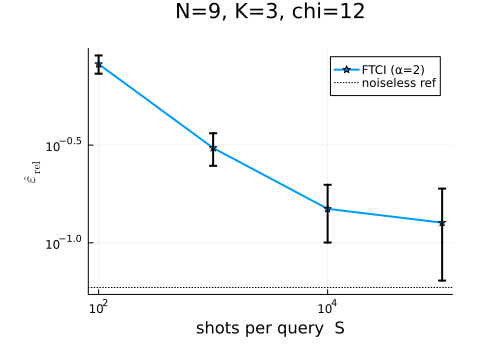

Figure saved.


In [14]:
# ── Plot: relative error vs shots per query (single panel, pb) ───────────────
# Reload from checkpoint if the kernel was restarted (run cells 1–2 first).
if !(@isdefined(results))
    results = deserialize(joinpath(DIR_PROCESSED, "noisy_sweep_N$(N_SINGLE)_chi$(CHI_MAX).jls"))["results"]
    @info "Loaded $(sum(length, values(results))) noisy runs from checkpoint."
end

S_fin   = sort([S for S in keys(results) if isfinite(S)])
mean_e  = [mean(r["eps_rel"] for r in results[S]) for S in S_fin]
std_e   = [std([r["eps_rel"] for r in results[S]])  for S in S_fin]
shots   = [mean(r["total_shots"] for r in results[S]) for S in S_fin]
eps_ref = haskey(results, Inf) ? results[Inf][1]["eps_rel"] : NaN

pb = plot(S_fin, mean_e; yerror=std_e, xscale=:log10, yscale=:log10,
          marker=:s, lw=2, label="FTCI (α=2)",
          xlabel="shots per query  S", ylabel=L"\hat\varepsilon_{\mathrm{rel}}",
          title="N=$N_SINGLE, K=$N_STEPS, chi=$CHI_MAX", legend=:topright,
          size=(480,360), margin=5Plots.mm)
#plot!(pb, S_fin, 1.0 ./ sqrt.(S_fin); ls=:dash, color=:gray, label=L"1/\sqrt{S}")
isfinite(eps_ref) && hline!(pb, [eps_ref]; ls=:dot, color=:black, label="noiseless ref")

display(pb)
savefig(pb, joinpath(DIR_FIGURES, "noisy_error_vs_shots_N$(N_SINGLE)_chi$(CHI_MAX)_$(RUN_ID).svg"))
println("Figure saved.")

In [12]:
# ── Summary table (for manuscript text) ─────────────────────────────────────
mean_n = [mean(r["n_calls"] for r in results[S]) for S in S_fin]
@printf("%-10s %-12s %-10s %-14s\n", "S", "eps_rel(mean)", "calls", "total shots")
for (S, me, mn, sh) in zip(S_fin, mean_e, mean_n, shots)
    @printf("%-10.0e %-12.3e %-10.0f %-14.2e\n", S, me, mn, sh)
end
isfinite(eps_ref) && @printf("%-10s %-12.3e\n", "Inf", eps_ref)

# Sanity expectations:
#  * eps_rel should track ~ const/sqrt(S) until it hits the noiseless floor
#  * no exponential blow-up: error at S=1e4 should be within ~1 order of 1/sqrt(S)


S          eps_rel(mean) calls      total shots   
1e+02      8.211e-01    6077101    6.08e+08      
1e+03      3.057e-01    6057460    6.06e+09      
1e+04      1.492e-01    6082067    6.08e+10      
1e+05      1.267e-01    6809627    6.81e+11      
Inf        5.909e-02   


## Oversampling necessity — α = 1, 2, 3

Same Heisenberg setting (N, K, χ, oracle, validation set) as above; the only knob
changed is the oversampling α (M^(k) = α·d_k). For each α we

1. rebuild the random nodes `a_vec_list_α` and design matrices V^(k),
2. record the analytic amplification factor `∏ₖ‖V^(k)+‖₂` (no FTCI needed), and
3. run the noisy FTCI over a light `S`-grid × seeds, reusing `fq`, `Js_val`, `y_true`.

The square design (α=1) is generically ill-conditioned, so the noise it injects into
the Fourier coefficients is amplified by `∏ₖ‖V^(k)+‖₂`; α ≥ 2 keeps that factor O(1).
Reuses `build_V` from the diagnostic cell.

In [8]:
# ── Oversampling sweep: design + analytic ||V+||, then light noisy FTCI ──────
ALPHA_LIST     = [1, 2, 3]
ALPHA_AMP      = 1:5                                   # α range for the analytic ||V+|| curve (cheap)
S_ALPHA        = QUICK_MODE ? [1e2, Inf] : [1e2, 1e4, Inf]
N_SEEDS_ALPHA  = QUICK_MODE ? 2 : 3

@isdefined(build_V) || error("Run the diagnostic cell (defines build_V) before this one.")

# design (nodes + amplification factor) and a per-α cached noiseless oracle
function make_alpha_design(α)
    Mα    = α .* phys_dims
    rng   = MersenneTwister(RNG_SEED)
    avl   = [domain_range[k] .* rand(rng, Mα[k]) for k in 1:4]
    amp   = prod(opnorm(pinv(build_V(ωss[k], avl[k]))) for k in 1:4)
    cache = Dict{NTuple{4,Int}, Float64}()
    fidx  = id -> get!(cache, Tuple(id)) do
        fq([avl[p][id[p]] for p in 1:4])
    end
    (M=Mα, avl=avl, amp=amp, fidx=fidx)
end

function run_alpha_point(des, α, S, seed)
    rng_noise = MersenneTwister(seed)
    σ = isinf(S) ? 0.0 : 1.0 / sqrt(S)
    f_noisy  = id -> des.fidx(id) + σ * randn(rng_noise)
    ctr      = CounterWithLog(; verbose=false)
    f_cached = counted_unique_with_log(f_noisy, ctr)
    tol = isinf(S) ? TCI_TOL0 : max(TCI_TOL0, TOL_FACTOR / sqrt(S))
    tci, _, _ = TCI.crossinterpolate2(Float64, f_cached, des.M; tolerance=tol, maxbonddim=CHI_MAX)
    cores_C = ttF_to_ttC(TCI.sitetensors(TCI.TensorTrain(tci)), ωss; auxs=des.avl)
    t_basis = make_basis_vectors(ωss, [J -> J[k] for k in 1:4])
    y_hat   = [eval_from_ttC(cores_C, t_basis, J) for J in Js_val]
    ε_rel   = sqrt(sum((y_true .- y_hat).^2)) / max(sqrt(sum(y_true.^2)), eps())
    Dict("alpha"=>α, "S"=>S, "seed"=>seed, "eps_rel"=>ε_rel,
         "n_calls"=>ctr.n, "amp"=>des.amp, "tol"=>tol)
end

# (b) analytic amplification factor vs α (no FTCI)
amp_curve = Dict{Int,Float64}()
for α in ALPHA_AMP
    des = make_alpha_design(α)
    amp_curve[α] = des.amp
    @printf("alpha=%d  M_k=%s  prod_k ||V+||_2 = %.3e\n", α, string(des.M), des.amp)
end

# (a) empirical noisy FTCI sweep over α × S × seed  (resumable checkpoint)
CKPT_A   = joinpath(DIR_PROCESSED, "alpha_sweep_N$(N_SINGLE)_chi$(CHI_MAX).jls")
config_A = Dict("N"=>N_SINGLE, "K"=>N_STEPS, "chi"=>CHI_MAX, "ALPHA_LIST"=>ALPHA_LIST,
                "S_ALPHA"=>S_ALPHA, "N_SEEDS_ALPHA"=>N_SEEDS_ALPHA, "M_VAL"=>M_VAL)
alpha_results = Dict{Tuple{Int,Float64}, Vector{Dict}}()
if isfile(CKPT_A)
    prev = deserialize(CKPT_A)
    if get(prev, "config", nothing) == config_A
        alpha_results = prev["results"]
        ndone = isempty(alpha_results) ? 0 : sum(length, values(alpha_results))
        @info "Resuming alpha sweep ($ndone runs already done): $CKPT_A"
    else
        @warn "alpha checkpoint config mismatch — starting fresh."
    end
end
a_done(α, S, sd) = haskey(alpha_results, (α, Float64(S))) &&
                   any(r -> r["seed"] == sd, alpha_results[(α, Float64(S))])
function save_alpha(res, cfg, amp, path)        # atomic overwrite
    tmp = path * ".tmp"
    serialize(tmp, Dict("results"=>res, "config"=>cfg, "amp_curve"=>amp))
    mv(tmp, path; force=true)
end

for α in ALPHA_LIST
    des = make_alpha_design(α)
    for S in S_ALPHA
        seeds  = isinf(S) ? [RNG_SEED] : [RNG_SEED + i for i in 0:N_SEEDS_ALPHA-1]
        bucket = get!(alpha_results, (α, Float64(S)), Dict[])
        for sd in seeds
            if a_done(α, S, sd)
                @printf("skip  alpha=%d S=%-8s seed=%d\n", α, string(S), sd); continue
            end
            r = run_alpha_point(des, α, S, sd)
            @printf("alpha=%d S=%-8s seed=%d   eps_rel=%.3e   amp=%.2e   calls=%d\n",
                    α, string(S), sd, r["eps_rel"], r["amp"], r["n_calls"])
            push!(bucket, r)
            save_alpha(alpha_results, config_A, amp_curve, CKPT_A)
        end
    end
end
save_alpha(alpha_results, config_A, amp_curve, CKPT_A)
println("Alpha sweep complete. Results in: $CKPT_A")

LoadError: Run the diagnostic cell (defines build_V) before this one.

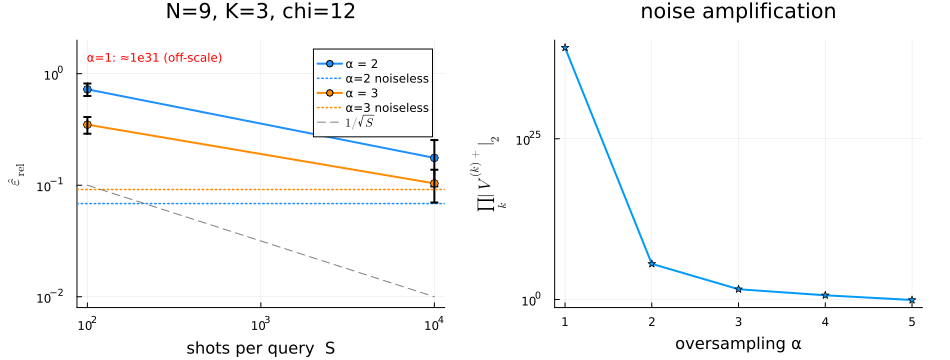

Oversampling figure saved.


In [9]:
# ── Oversampling figure: (a) error vs S per α (α≥2 zoom), (b) ∏‖V+‖₂ vs α ─────
# Reload from checkpoint if the kernel was restarted (run cells 1–2 first for config/imports).
if !(@isdefined(alpha_results)) || !(@isdefined(amp_curve))
    _a = deserialize(joinpath(DIR_PROCESSED, "alpha_sweep_N$(N_SINGLE)_chi$(CHI_MAX).jls"))
    alpha_results = _a["results"]
    amp_curve     = _a["amp_curve"]
    @info "Loaded $(sum(length, values(alpha_results))) α-runs + amp_curve from checkpoint."
end

αs_emp  = sort(unique(k[1] for k in keys(alpha_results)))            # α's with empirical runs
S_fin_A = sort(unique(S for (α, S) in keys(alpha_results) if isfinite(S)))

# panel (a): zoom to the usable α≥2 range; α=1 (~10^31) is off-scale and annotated.
pa = plot(; xscale=:log10, yscale=:log10, xlabel="shots per query  S",
          ylabel=L"\hat\varepsilon_{\mathrm{rel}}", ylims=(8e-3, 2.0),
          title="N=$N_SINGLE, K=$N_STEPS, chi=$CHI_MAX", legend=:topright)
cols = [:dodgerblue, :darkorange, :seagreen, :purple]   # per-α colour: curve + its noiseless dotted share it
for (i, α) in enumerate(filter(!=(1), αs_emp))          # α=1 is off-scale (annotated below)
    col = cols[mod1(i, length(cols))]
    me = [mean(r["eps_rel"] for r in alpha_results[(α, S)]) for S in S_fin_A]
    se = [std([r["eps_rel"] for r in alpha_results[(α, S)]]) for S in S_fin_A]
    plot!(pa, S_fin_A, me; yerror=se, marker=:o, lw=2, color=col, label="α = $α")
    haskey(alpha_results, (α, Inf)) &&
        hline!(pa, [alpha_results[(α, Inf)][1]["eps_rel"]]; ls=:dot, lw=1.5, color=col,
               label="α=$α noiseless")
end
plot!(pa, S_fin_A, 1.0 ./ sqrt.(S_fin_A); ls=:dash, color=:gray, label=L"1/\sqrt{S}")
if 1 in αs_emp
    e1 = mean(r["eps_rel"] for r in alpha_results[(1, first(S_fin_A))])
    annotate!(pa, first(S_fin_A), 1.4,
              text("α=1: ≈1e$(round(Int, log10(e1))) (off-scale)", 8, :red, :left))
end

# panel (b): amplification factor ∏‖V+‖₂ vs α  (α = 1..5)
αv   = sort(collect(keys(amp_curve)))
ampv = [amp_curve[α] for α in αv]
pbv  = plot(αv, ampv; marker=:s, lw=2, yscale=:log10, legend=false,
            xlabel="oversampling α", ylabel=L"\prod_k \|V^{(k)+}\|_2",
            title="noise amplification", xticks=αv)

pα = plot(pa, pbv; layout=(1, 2), size=(950, 360), margin=5Plots.mm)
display(pα)
savefig(pα, joinpath(DIR_FIGURES, "oversampling_alpha_N$(N_SINGLE)_chi$(CHI_MAX)_$(RUN_ID).svg"))
println("Oversampling figure saved.")

In [34]:
include("print_noisy_numbers.jl")

── main noisy sweep (fig:noisy) ──
S=100.0     eps_rel=8.211e-01 ± 8.8e-02   queries=6.077e+06   total_shots=6.077e+08
S=1000.0    eps_rel=3.057e-01 ± 5.8e-02   queries=6.057e+06   total_shots=6.057e+09
S=10000.0   eps_rel=1.492e-01 ± 4.9e-02   queries=6.082e+06   total_shots=6.082e+10
S=100000.0  eps_rel=1.267e-01 ± 6.3e-02   queries=6.81e+06   total_shots=6.810e+11
S=Inf       eps_rel=5.909e-02 ± 0.0e+00   queries=4.975e+06   total_shots=NaN
noiseless ref eps_rel = 5.909e-02

── amplification factor ∏‖V+‖ (fig:oversampling b) ──
alpha=1  amp=1.471e+39   (orders: 39.2)
alpha=2  amp=3.526e+05   (orders: 5.5)
alpha=3  amp=3.981e+01   (orders: 1.6)
alpha=4  amp=4.550e+00   (orders: 0.7)
alpha=5  amp=8.487e-01   (orders: -0.1)

── alpha empirical error (fig:oversampling a) ──
alpha=1 S=100.0     eps_rel=1.106e+31
alpha=1 S=10000.0   eps_rel=1.621e+28
alpha=1 S=Inf       eps_rel=1.360e-01
alpha=2 S=100.0     eps_rel=7.235e-01
alpha=2 S=10000.0   eps_rel=1.757e-01
alpha=2 S=Inf       eps_re